## AMY NJENGA- 668698
### Import the Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.metrics.pairwise import cosine_similarity
TOP_K=3

## Inspect the data

In [2]:
movies = pd.read_csv(r"C:\Users\jkaru\DSA4060-Week6-668698\DSA4060_Week6_Movies.csv")
ratings = pd.read_csv(r"C:\Users\jkaru\DSA4060-Week6-668698\DSA4060_Week6_Ratings.csv")
display(movies.head())
display(ratings.head())
print("Users:", ratings["user_id"].nunique())
print("Movies:", ratings["movie_id"].nunique())
print("Ratings:", len(ratings))

,movie_id,title,genres
0,1,Galaxy Mission,Action|Sci-Fi
1,2,Love in Nairobi,Romance|Drama
2,3,Final Battle,Action
3,4,Family Weekend,Comedy|Family
4,5,Future World,Sci-Fi|Action


,user_id,movie_id,rating,timestamp
0,1,2,3,1
1,1,10,3,2
2,1,1,5,3
3,1,9,3,4
4,1,7,3,5


Users: 12
Movies: 20
Ratings: 120


1. What does one row in movies represent?

It represents a single movie including its id, name and genre

2. What does one row in ratings represent?

It represents a singular rating for one movie by one user

3. How many unique users and movies are present?

Unique users are 12

unique moies are 20

4. What type of feedback is the rating column?

The rating column is explicit feedback on the extent to whic the user enjoyed the movie

5. What is the rating scale?

The scale is from 1-5

### Inspect the rating behaviour

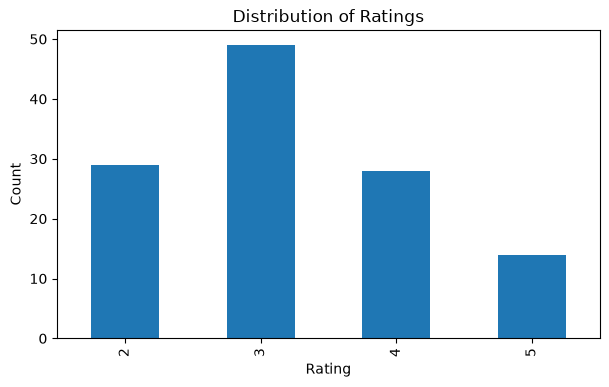

In [3]:
ratings["rating"].value_counts().sort_index()
plt.figure(figsize=(7,4))
ratings["rating"].value_counts().sort_index().plot(kind="bar")
plt.title("Distribution of Ratings")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.show()

it seems like average ratings of 3 dominate the data wich could potentially affect evaluation by having a low precision@3

### Create a Train/Test Split

In [4]:
ratings = ratings.sort_values(["user_id", "timestamp"])
test = ratings.groupby("user_id").tail(1).copy()
train = ratings.drop(test.index).copy()
print("Training interactions:", len(train))
print("Test interactions:", len(test))
display(test.head())

Training interactions: 108
Test interactions: 12


,user_id,movie_id,rating,timestamp
9,1,14,4,10
19,2,9,4,20
29,3,18,3,30
39,4,18,3,40
49,5,11,2,50


### Build a Popularity Baseline

In [5]:
global_mean = train["rating"].mean()
movie_stats = (
train.groupby("movie_id")
.agg(
mean_rating=("rating", "mean"),
rating_count=("rating", "size")
)
.reset_index()
.merge(movies[["movie_id", "title"]], on="movie_id")
)
movie_stats.sort_values(
["mean_rating", "rating_count"],
ascending=[False, False]
).head(10)
movie_mean_map = train.groupby("movie_id")["rating"].mean().to_dict()
baseline_test = test.copy()
baseline_test["prediction"] = baseline_test["movie_id"].map(movie_mean_map)
baseline_test["prediction"] = baseline_test["prediction"].fillna(global_mean)

### Evaluate Baseline with MAE and RMSE

In [6]:
def rating_metrics(actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    return mae, rmse

baseline_mae, baseline_rmse = rating_metrics(
    baseline_test["rating"],
    baseline_test["prediction"]
)
print("Baseline MAE:", round(baseline_mae, 3))
print("Baseline RMSE:", round(baseline_rmse, 3))

Baseline MAE: 1.086
Baseline RMSE: 1.201


### Build Item Features for Content-Based Filtering

In [7]:
genre_features = movies["genres"].str.get_dummies(sep="|")
content_items = pd.concat(
[movies[["movie_id", "title"]], genre_features],
axis=1
)
genre_columns = genre_features.columns.tolist()
item_feature_matrix = content_items.set_index("movie_id")[genre_columns]
display(content_items.head())

,movie_id,title,Action,Adventure,Comedy,Crime,Drama,Family,Mystery,Romance,Sci-Fi
0,1,Galaxy Mission,1,0,0,0,0,0,0,0,1
1,2,Love in Nairobi,0,0,0,0,1,0,0,1,0
2,3,Final Battle,1,0,0,0,0,0,0,0,0
3,4,Family Weekend,0,0,1,0,0,1,0,0,0
4,5,Future World,1,0,0,0,0,0,0,0,1


### Build User Profile

In [8]:
def build_user_profile(user_id, train_data):
    history = train_data[train_data["user_id"] == user_id]

    ids = history["movie_id"].values
    ratings_array = history["rating"].values.reshape(-1, 1)
    features = item_feature_matrix.loc[ids].values
    
    return (features * ratings_array).mean(axis=0)
profile = build_user_profile(1, train)

pd.Series( 
    profile,
    index=genre_columns
).sort_values(ascending=False)

Drama        1.666667
Sci-Fi       1.000000
Comedy       0.888889
Romance      0.666667
Action       0.555556
Family       0.555556
Crime        0.333333
Mystery      0.333333
Adventure    0.222222
dtype: float64

User 1’s top genres are Drama with 1.67 and Sci-Fi with 1.00. They agree with the user’s best ratings: Galaxy Mission (Action,Sci-Fi, 5) and Digital Dreams (Sci-Fi,Drama, 4).

### Content-based rating prediction

In [9]:
def content_score(user_id, movie_id, train_data):
    profile = build_user_profile(user_id, train_data).reshape(1, -1)
    item_vec = item_feature_matrix.loc[movie_id].values.reshape(1, -1)
    
    sim = cosine_similarity(profile, item_vec)[0, 0]
    
    return float(np.clip(1 + 4 * sim, 1, 5))

content_test = test.copy()
content_test["prediction"] = content_test.apply(
    lambda r: content_score(r["user_id"], r["movie_id"], train),
    axis=1
)
content_mae, content_rmse = rating_metrics(
    content_test["rating"],
    content_test["prediction"]
)
print("Content MAE:", round(content_mae, 3))
print("Content RMSE:", round(content_rmse, 3))

Content MAE: 1.094
Content RMSE: 1.381


### Item-based collaborative filtering

In [10]:
user_item = train.pivot_table(
    index="user_id",
    columns="movie_id",
    values="rating"
)

item_user = user_item.T.fillna(0)

item_similarity = pd.DataFrame(
    cosine_similarity(item_user),
    index=item_user.index,
    columns=item_user.index
)
item_similarity.iloc[:5, :5]

movie_id,1,2,3,4,5
movie_id,,,,,
1,1.000000,0.314450,0.391983,0.440908,0.132518
2,0.314450,1.000000,0.645526,0.569308,0.543524
3,0.391983,0.645526,1.000000,0.509175,0.196760
4,0.440908,0.569308,0.509175,1.000000,0.468868
5,0.132518,0.543524,0.196760,0.468868,1.000000


### Item-based Rating Prediction

In [11]:
def item_cf_predict(user_id, movie_id, train_data): 
    history = train_data[train_data["user_id"] == user_id]

    weighted_sum = 0.0
    similarity_sum = 0.0
    
    for row in history.itertuples():
        if movie_id in item_similarity.index and row.movie_id in item_similarity.columns:
            sim = item_similarity.loc[movie_id, row.movie_id]
        
        if sim > 0:
            weighted_sum += sim * row.rating
            similarity_sum += sim

    if similarity_sum == 0:
        return global_mean
    
    return weighted_sum / similarity_sum

cf_test = test.copy()
cf_test["prediction"] = cf_test.apply(
    lambda r: item_cf_predict(r["user_id"], r["movie_id"], train),
    axis=1
)
cf_mae, cf_rmse = rating_metrics(
    cf_test["rating"],
    cf_test["prediction"]
)
print("CF MAE:", round(cf_mae, 3))
print("CF RMSE:", round(cf_rmse, 3))

CF MAE: 0.924
CF RMSE: 1.07


### Compare rating predictions

In [12]:
rating_results = pd.DataFrame({
    "Model": [
        "Popularity Baseline",
        "Content-Based",
        "Item-Based CF"
],

"MAE": [baseline_mae, content_mae, cf_mae],
"RMSE": [baseline_rmse, content_rmse, cf_rmse]
})
rating_results.sort_values("MAE")

,Model,MAE,RMSE
2,Item-Based CF,0.924315,1.069675
0,Popularity Baseline,1.085913,1.201011
1,Content-Based,1.093920,1.380701


6. Which model has the lowest MAE?

Item-based Cf

7. Which model has the lowest RMSE?

Item-based CF

8. Does either advanced model clearly beat the baseline?

CF beats the baseline modestly on both metrics. Content-based does not: it is slightly worse on MAE and clearly worse on RMSE.

9. Why should you avoid declaring a model best from only one metric?

MAE and RMSE only measure rating error. They say nothing about ranking quality, coverage, novelty or diversity. In this run CF has the best rating error but 0 ranking hits.


### From rating prediction to ranking evaluation

In [13]:
test["relevant"] = test["rating"] >= 4
test[["user_id", "movie_id", "rating", "relevant"]].head()

,user_id,movie_id,rating,relevant
9,1,14,4,True
19,2,9,4,True
29,3,18,3,False
39,4,18,3,False
49,5,11,2,False


### Build Top-N Recommendation Fucntions

In [14]:
all_movie_ids = movies["movie_id"].tolist()

def unseen_movies(user_id):
    seen = set(
        train.loc[train["user_id"] == user_id, "movie_id"]
)
    return [m for m in all_movie_ids if m not in seen]

popularity_order = (
    movie_stats
    .sort_values(["mean_rating", "rating_count"], ascending=[False, False])
    ["movie_id"].tolist()
)

def recommend_popularity(user_id, k=3):
    unseen = set(unseen_movies(user_id))
    return [m for m in popularity_order if m in unseen][:k]

def recommend_content(user_id, k=3):
    scored = [(m, content_score(user_id, m, train)) for m in unseen_movies(user_id)]
    scored.sort(key=lambda x: x[1], reverse=True)
    return [m for m, s in scored[:k]]

def recommend_cf(user_id, k=3):
    scored = [(m, item_cf_predict(user_id, m, train)) for m in unseen_movies(user_id)]
    scored.sort(key=lambda x: x[1], reverse=True)
    return [m for m, s in scored[:k]]
print("Popularity:", recommend_popularity(1))
print("Content:", recommend_content(1))
print("Collaborative:", recommend_cf(1))


Popularity: [6, 18, 16]
Content: [16, 6, 18]
Collaborative: [12, 11, 18]


For User 1 the lists are Popularity [6, 18, 16], Content [16, 6, 18] and CF [12, 11, 18]. Content is the same set as Popularity, just reordered, so CF looks most different from the others. Popularity is the easiest to explain (“highest rated”). Content is easy too (“matches your genres”).

### Precision@K, Recall@K, NDCG@K

In [15]:
def precision_recall_at_k(recs, relevant, k):
    recs = recs[:k]
    hits = len(set(recs) & set(relevant))
    
    precision = hits / k
    recall = hits / len(relevant) if relevant else np.nan
    
    return precision, recall

def ndcg_at_k(recs, relevant, k):
    dcg = 0.0
    
    for rank, movie_id in enumerate(recs[:k], start=1):
        if movie_id in relevant:
            dcg += 1 / np.log2(rank + 1)
        
    ideal_hits = min(len(relevant), k)
    idcg = sum(
        1 / np.log2(rank + 1)
        for rank in range(1, ideal_hits + 1)
    )
    return dcg / idcg if idcg > 0 else np.nan

def evaluate_ranking(recommender, k=3):
    rows = []
    
    for user_id in sorted(test["user_id"].unique()):
        relevant = test.loc[
            (test["user_id"] == user_id) &
            (test["rating"] >= 4),
            "movie_id"
        ].tolist()
        if not relevant:
            continue


        recs = recommender(user_id, k)
        precision, recall = precision_recall_at_k(recs, relevant, k)

        rows.append({
            "user_id": user_id,
            "Precision@K": precision,
            "Recall@K": recall,
            "NDCG@K": ndcg_at_k(recs, relevant, k)
        })

    result = pd.DataFrame(rows)


    return {
        "Precision@3": result["Precision@K"].mean(),
        "Recall@3": result["Recall@K"].mean(),
        "NDCG@3": result["NDCG@K"].mean()
    }

pop_rank = evaluate_ranking(recommend_popularity, TOP_K)
content_rank = evaluate_ranking(recommend_content, TOP_K)
cf_rank = evaluate_ranking(recommend_cf, TOP_K)

ranking_results = pd.DataFrame([
    {"Model": "Popularity Baseline", **pop_rank},
    {"Model": "Content-Based", **content_rank},
    {"Model": "Item-Based CF", **cf_rank}
])

ranking_results

,Model,Precision@3,Recall@3,NDCG@3
0,Popularity Baseline,0.066667,0.2,0.1
1,Content-Based,0.066667,0.2,0.2
2,Item-Based CF,0.000000,0.0,0.0


### Catalogue Coverage

In [16]:
def catalogue_coverage(recommender, k=3):
    recommended = set()
    
    for user_id in train["user_id"].unique():
        recommended.update(recommender(user_id, k))
        
    return len(recommended) / movies["movie_id"].nunique()
coverage_results = pd.DataFrame({
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
    "Coverage": [
        catalogue_coverage(recommend_popularity),
        catalogue_coverage(recommend_content),
        catalogue_coverage(recommend_cf)
   ] 
})

coverage_results

,Model,Coverage
0,Popularity Baseline,0.35
1,Content-Based,0.70
2,Item-Based CF,0.85


### Novelty

In [17]:
pop_counts = train["movie_id"].value_counts().to_dict()
num_users = train["user_id"].nunique()

def novelty_of_item(movie_id):
    p = pop_counts.get(movie_id, 1) / num_users
    return -np.log2(p)


def average_novelty(recommender, k=3):
    values = []
    
    for user_id in train["user_id"].unique():
        recs = recommender(user_id, k)
        values.extend([novelty_of_item(m) for m in recs])

    return np.mean(values)

novelty_results = pd.DataFrame({
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
    "Novelty": [
        average_novelty(recommend_popularity),
        average_novelty(recommend_content),
        average_novelty(recommend_cf)
    ]
})
novelty_results

,Model,Novelty
0,Popularity Baseline,1.689432
1,Content-Based,1.343556
2,Item-Based CF,1.694791


### Diversity

In [18]:
genre_similarity = pd.DataFrame(
    cosine_similarity(item_feature_matrix),
    index=item_feature_matrix.index,
    columns=item_feature_matrix.index
)


def list_diversity(movie_ids):
    sims = []

    for i in range(len(movie_ids)):
        for j in range(i + 1, len(movie_ids)):
            sims.append(
                genre_similarity.loc[movie_ids[i], movie_ids[j]]
            )
    return 1 - np.mean(sims) if sims else 0

def average_diversity(recommender, k=3):
    return np.mean([
        list_diversity(recommender(user_id, k))
        for user_id in train["user_id"].unique()
    ])

diversity_results = pd.DataFrame({
    "Model": ["Popularity Baseline", "Content-Based", "Item-Based CF"],
    "Diversity": [
        average_diversity(recommend_popularity),
        average_diversity(recommend_content),
        average_diversity(recommend_cf)
    ]
})
diversity_results

,Model,Diversity
0,Popularity Baseline,0.736111
1,Content-Based,0.541667
2,Item-Based CF,0.780161


### Unified Evaluation Table

In [19]:
summary = (
    rating_results
    .merge(ranking_results, on="Model")
    .merge(coverage_results, on="Model")
    .merge(novelty_results, on="Model")
    .merge(diversity_results, on="Model")
)
summary

,Model,MAE,RMSE,Precision@3,Recall@3,NDCG@3,Coverage,Novelty,Diversity
0,Popularity Baseline,1.085913,1.201011,0.066667,0.2,0.1,0.35,1.689432,0.736111
1,Content-Based,1.093920,1.380701,0.066667,0.2,0.2,0.70,1.343556,0.541667
2,Item-Based CF,0.924315,1.069675,0.000000,0.0,0.0,0.85,1.694791,0.780161


Assume you are advising a new streaming service. Management says:
“We want users to discover relevant movies, but we do not want the same popular titles to dominate every
recommendation list.”
10. Which model would you choose?

Content-Based

11. Which 2–3 metrics influenced your choice most?

NDCG@3 (it has the best ranking score), Recall@3 (tied best with popularity) and Coverage (0.70 vs 0.35)

12. What trade-off are you accepting?

Lower diversity (0.54) and novelty (1.34) than the other two models, plus worse rating accuracy than CF

13. State one limitation of this evaluation.

The test set is tiny. There are 12 users with one held-out item each, and only 5 relevant items. One extra hit moves Recall@3 by 0.2, so the model ranking is not statistically reliable


Option A – Change K: evaluate K = 1, 3 and 5, then explain how Precision@K and Recall@K change

,K,Model,Precision@K,Recall@K
0,1,Popularity Baseline,0.000000,0.0
1,1,Content-Based,0.200000,0.2
2,1,Item-Based CF,0.000000,0.0
3,3,Popularity Baseline,0.066667,0.2
4,3,Content-Based,0.066667,0.2
5,3,Item-Based CF,0.000000,0.0
6,5,Popularity Baseline,0.040000,0.2
7,5,Content-Based,0.080000,0.4
8,5,Item-Based CF,0.040000,0.2


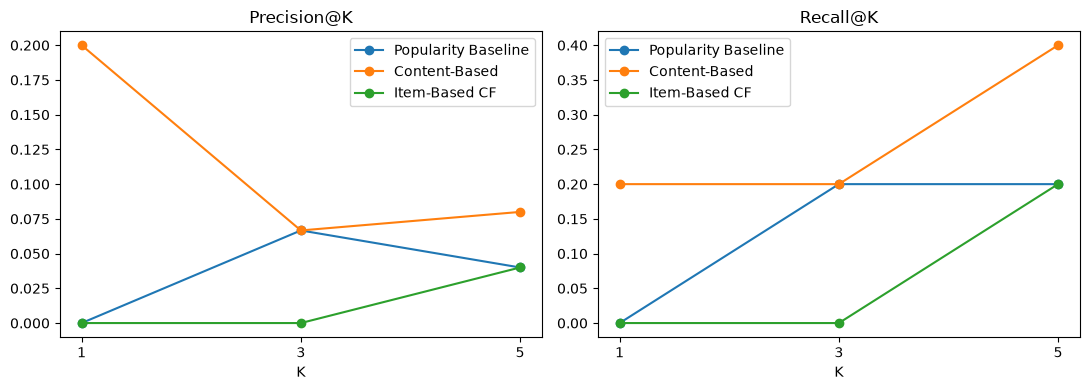

In [20]:
# Option A – Change K (evaluate K = 1, 3, 5)
models = {
    "Popularity Baseline": recommend_popularity,
    "Content-Based": recommend_content,
    "Item-Based CF": recommend_cf
}

k_rows = []
for k in [1, 3, 5]:
    for name, rec in models.items():
        r = evaluate_ranking(rec, k)   # dict keys say "@3" but values are computed at this k
        k_rows.append({
            "K": k,
            "Model": name,
            "Precision@K": r["Precision@3"],
            "Recall@K": r["Recall@3"]
        })

k_results = pd.DataFrame(k_rows)
display(k_results)

# Plots
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name in models:
    sub = k_results[k_results["Model"] == name]
    axes[0].plot(sub["K"], sub["Precision@K"], marker="o", label=name)
    axes[1].plot(sub["K"], sub["Recall@K"], marker="o", label=name)
axes[0].set_title("Precision@K"); axes[1].set_title("Recall@K")
for ax in axes:
    ax.set_xlabel("K"); ax.set_xticks([1, 3, 5]); ax.legend()
plt.tight_layout()
plt.show()

As K increases, Recall@K rises or stays flat, because longer lists can catch more relevant items. Precision@K tends to fall, because each extra slot is less likely to be a hit. With only 5 relevant test items, these curves are noisy, so one hit can change the result noticeably.